# 1. Data: from tick quotes to daily realized variance

This notebook builds the daily dataset that the forecasting study uses and checks
the choice of 5-minute sampling.

1. Download EUR/USD tick quotes from Dukascopy.
2. Turn them into one realized variance (RV) per FX session.
3. Audit the daily dataset.
4. Check how fine prices can be sampled before bid–ask noise biases RV.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from rvol.data.parquet import ParquetDatasetRepository
from rvol.data.volatility.coverage import audit_daily_dataset
from rvol.data.volatility.dataset import build_daily_dataset
from rvol.estimators.diagnostics import noise_test, signature

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIGURES = ROOT / "figures"
TICKS = ROOT / "data/ticks/EURUSD"
DAILY = ROOT / "data/derived/EURUSD_daily_rv_5min.parquet"
DIAGNOSTICS_QUARTER = "EURUSD_2024-01-01_2024-03-31"

# True rebuilds the daily dataset from every tick file; this reads about 1 GB.
REBUILD_DAILY = False

PRICE_STYLE = {
    "mid": {"color": "tab:blue", "marker": "o"},
    "bid": {"color": "tab:orange", "marker": "s"},
    "ask": {"color": "tab:green", "marker": "^"},
}

## Download

Tick quotes are downloaded outside the notebook, one quarter per call:

```sh
python -m rvol.data.sources.dukascopy EURUSD 2023-01-01 2023-03-31
```

Raw hourly files are cached in `data/raw/dukascopy/EURUSD/` and decoded quotes
(time, bid, ask, quoted sizes, mid) are written to `data/ticks/EURUSD/`.

## Daily realized variance

Each tick is assigned to an FX session ending at 17:00 New York time. Within a
session the mid price is sampled every 5 minutes (last quote in each bin), and
RV is the sum of squared 5-minute log returns. Sessions shorter than 12 hours
(holidays, the Sunday open) are dropped.

In [2]:
if REBUILD_DAILY or not DAILY.exists():
    daily = build_daily_dataset(sorted(TICKS.glob("EURUSD_*.parquet")))
    ParquetDatasetRepository(DAILY).save(daily)
else:
    daily = ParquetDatasetRepository(DAILY).load()
daily.tail()

,date,rv_5min,log_rv,observation_count
968,2026-09-25,0.000008,-11.701473,288
969,2026-09-28,0.000012,-11.337759,288
970,2026-09-29,0.000011,-11.395401,288
971,2026-09-30,0.000013,-11.226630,288
972,2026-10-01,0.000027,-10.538294,288


In [3]:
audit = audit_daily_dataset(daily)
assert audit.passed, "the daily dataset failed its audit"
pd.Series(
    {
        "sessions": audit.n_sessions,
        "first session": audit.start_date.date(),
        "last session": audit.end_date.date(),
        "median 5-minute observations": audit.median_observation_count,
        "sessions with unusual counts": audit.unusual_observation_sessions,
        "gaps longer than 7 days": len(audit.large_gaps),
        **{f"sessions in {year.year}": year.sessions for year in audit.sessions_by_year},
    },
    name="audit",
).to_frame()

,audit
sessions,973
first session,2023-01-02
last session,2026-10-01
median 5-minute observations,288.0
sessions with unusual counts,0
gaps longer than 7 days,0
sessions in 2023,259
sessions in 2024,260
sessions in 2025,259
sessions in 2026,195


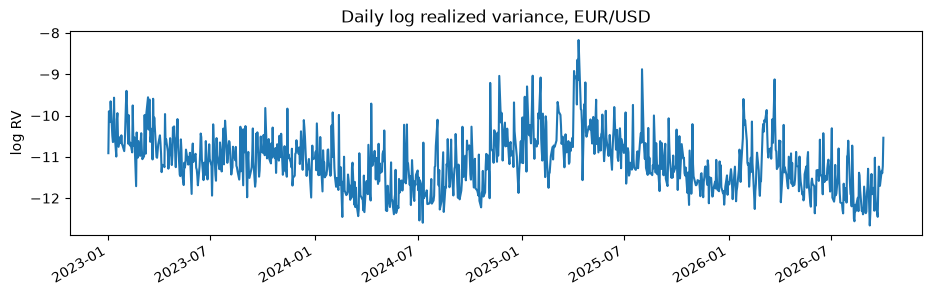

In [4]:
daily.set_index("date")["log_rv"].plot(
    figsize=(11, 3), title="Daily log realized variance, EUR/USD", ylabel="log RV", xlabel=""
);

## How fine can prices be sampled?

Sampling more often uses more data, but at very fine intervals bid–ask noise adds
to every return and inflates RV. The signature plot shows mean RV across sessions
at sampling intervals from 1 second to 1 hour, annualised. A flat curve means
noise is negligible at that frequency.

In [5]:
ticks = pd.read_parquet(TICKS / f"{DIAGNOSTICS_QUARTER}.parquet")
signatures = {price: signature(ticks, price) for price in ("mid", "bid", "ask")}
signatures["mid"]

,freq,seconds,mean_RV,ann_vol_pct,n_days,se,ann_vol_se
0,1s,1.0,0.000013,5.782160,64,1.035581e-06,0.225665
1,2s,2.0,0.000013,5.810130,64,9.961765e-07,0.216033
2,5s,5.0,0.000014,5.883520,64,1.015755e-06,0.217532
3,10s,10.0,0.000014,5.894172,64,1.006246e-06,0.215106
4,15s,15.0,0.000014,5.928146,64,1.084843e-06,0.230578
5,30s,30.0,0.000014,5.891622,64,1.079932e-06,0.230958
6,1min,60.0,0.000013,5.787624,64,1.068517e-06,0.232622
7,2min,120.0,0.000014,5.885549,64,1.260911e-06,0.269940
8,5min,300.0,0.000013,5.632802,64,1.137093e-06,0.254356
9,10min,600.0,0.000012,5.608118,64,1.138677e-06,0.255831


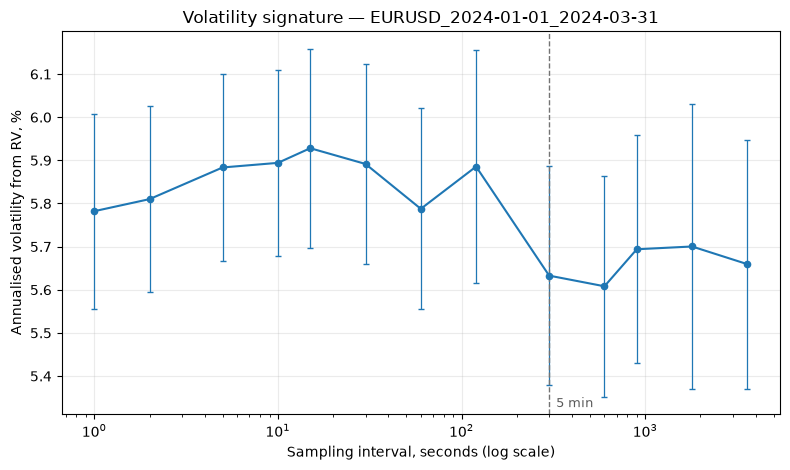

In [6]:
def draw_signature(price: str, values: pd.DataFrame, title: str):
    """Annualised volatility from RV at each sampling interval, with standard errors."""
    figure, axis = plt.subplots(figsize=(8.0, 4.8))
    style = PRICE_STYLE[price]
    axis.errorbar(
        values["seconds"],
        values["ann_vol_pct"],
        yerr=values["ann_vol_se"],
        color=style["color"],
        marker=style["marker"],
        label=price,
        linewidth=1.5,
        markersize=4.5,
        capsize=2.5,
        elinewidth=0.9,
    )
    axis.axvline(300, linestyle="--", linewidth=1, color="0.45")
    axis.annotate("5 min", xy=(300, axis.get_ylim()[0]), xytext=(5, 5),
                  textcoords="offset points", color="0.35", fontsize=9)
    axis.set_xscale("log")
    axis.set_xlabel("Sampling interval, seconds (log scale)")
    axis.set_ylabel("Annualised volatility from RV, %")
    axis.set_title(title)
    axis.grid(alpha=0.25)
    figure.tight_layout()
    return figure


fig = draw_signature("mid", signatures["mid"], f"Volatility signature — {DIAGNOSTICS_QUARTER}")
fig.savefig(FIGURES / "signature_plot.png", dpi=150)

Mid prices give an almost flat curve. Bid prices, where the bounce between bid and
ask is not averaged away, show the upward slope that noise produces:

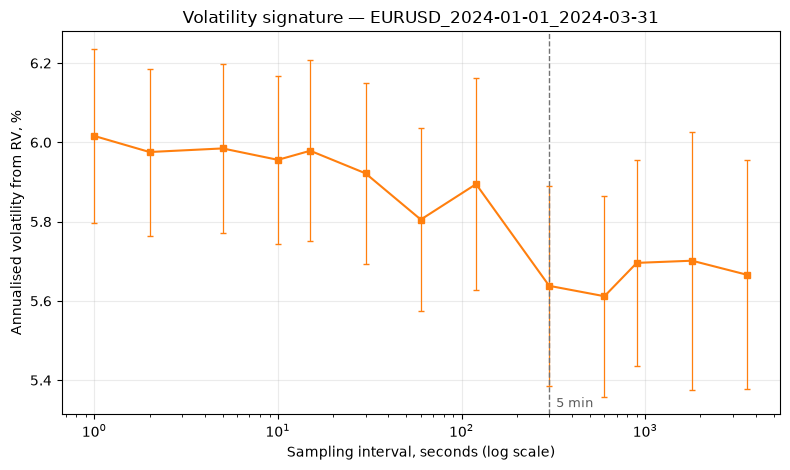

In [7]:
fig = draw_signature("bid", signatures["bid"], f"Volatility signature — {DIAGNOSTICS_QUARTER}")
fig.savefig(FIGURES / "signature_bid.png", dpi=150)

## Paired noise test

Comparing two averages is weak, because a volatile week raises RV at every
frequency at once. Pairing by session — one ratio RV(1s)/RV(5min) per session,
then a one-sided t-test on the log ratios — removes that shared variation. The
implied noise standard deviation comes from E[RV_n] = IV + 2nω².

In [8]:
noise = {price: noise_test(ticks, price, fine="1s", coarse="5min") for price in signatures}
pd.DataFrame(
    {
        price: {
            "RV(1s) / RV(5min)": result.mean_ratio,
            "t": result.t_stat,
            "one-sided p": result.p_value,
            "implied noise sd, bps": result.implied_noise_bps,
            "sessions": result.n_days,
        }
        for price, result in noise.items()
    }
).T

,RV(1s) / RV(5min),t,one-sided p,"implied noise sd, bps",sessions
mid,1.077959,2.548257,6.638375e-03,0.029678,64.0
bid,1.179357,5.290692,8.170896e-07,0.048773,64.0
ask,1.181057,5.430344,4.807177e-07,0.048479,64.0


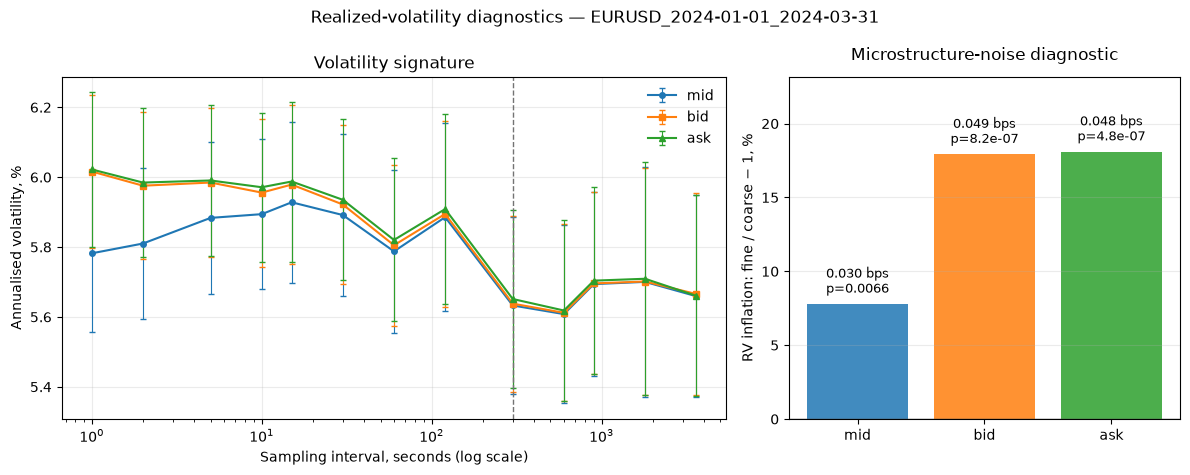

In [9]:
figure, (signature_axis, noise_axis) = plt.subplots(
    1, 2, figsize=(12.0, 4.8), gridspec_kw={"width_ratios": [1.7, 1]}
)
for price, values in signatures.items():
    style = PRICE_STYLE[price]
    signature_axis.errorbar(
        values["seconds"],
        values["ann_vol_pct"],
        yerr=values["ann_vol_se"],
        color=style["color"],
        marker=style["marker"],
        label=price,
        linewidth=1.5,
        markersize=4,
        capsize=2,
        elinewidth=0.8,
    )
signature_axis.axvline(300, linestyle="--", linewidth=1, color="0.45")
signature_axis.set_xscale("log")
signature_axis.set_xlabel("Sampling interval, seconds (log scale)")
signature_axis.set_ylabel("Annualised volatility, %")
signature_axis.set_title("Volatility signature")
signature_axis.grid(alpha=0.25)
signature_axis.legend(frameon=False)

inflation = np.array([result.mean_ratio - 1 for result in noise.values()]) * 100
bars = noise_axis.bar(
    list(noise), inflation, color=[PRICE_STYLE[price]["color"] for price in noise], alpha=0.85
)
noise_axis.axhline(0, linewidth=1, color="0.35")
noise_axis.set_ylim(0, float(np.max(inflation)) * 1.28)
noise_axis.set_ylabel("RV inflation: fine / coarse − 1, %")
noise_axis.set_title("Microstructure-noise diagnostic", pad=12)
noise_axis.grid(axis="y", alpha=0.25)
for bar, result in zip(bars, noise.values(), strict=True):
    noise_axis.annotate(
        f"{result.implied_noise_bps:.3f} bps\np={result.p_value:.2g}",
        xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=9,
    )
figure.suptitle(f"Realized-volatility diagnostics — {DIAGNOSTICS_QUARTER}")
figure.tight_layout()
figure.savefig(FIGURES / "diagnostics_overview.png", dpi=160)

**Conclusion.** Noise in EUR/USD mid quotes is real but small: sampling every
second inflates variance by under 10%. Five-minute sampling is therefore a
conservative choice for this instrument, and the forecasting study uses it.